In [1]:
import json
import time
from pathlib import Path

import ignite
import kagglehub
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torchvision
from ignite.metrics import FID, InceptionScore
from PIL import Image
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from torchvision.utils import make_grid, save_image

device = torch.device("mps")
torch.set_num_threads(4)
seed = 66
torch.manual_seed(seed)
repo_root = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file()
)
run_dir = repo_root / "hw2" / "checkpoints"
run_dir.mkdir(parents=True, exist_ok=True)

## setup data

In [2]:
kagglehub.dataset_download(
    "steubk/wikiart",
    output_dir=str(repo_root / "hw2" / "data" / "wikiart"),
)

'/Users/sriram/ucsd/ECE285DGM/hw2/data/wikiart'

In [3]:
data_root = repo_root / "hw2/data/wikiart"

transform = transforms.Compose(
    [
        transforms.Resize(64),
        transforms.CenterCrop(64),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=(0.5, 0.5, 0.5),
            std=(0.5, 0.5, 0.5),
        ),
    ]
)
dataset = datasets.ImageFolder(
    root=data_root,
    transform=transform,
    allow_empty=True,
)

indices = torch.randperm(
    len(dataset), generator=torch.Generator().manual_seed(seed)
).tolist()
selected_indices = []
seen = set()
for index in indices:
    name = Path(dataset.samples[index][0]).name
    if name not in seen:
        selected_indices.append(index)
        seen.add(name)

train_dataset = Subset(dataset, selected_indices[:20000])
eval_dataset = Subset(dataset, selected_indices[20000:21000])

loader_rng = torch.Generator().manual_seed(seed)
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True,
    generator=loader_rng,
    num_workers=8,
    persistent_workers=True,
)

## generator

In [4]:
z_dim = 100


class Generator(nn.Module):
    def __init__(self, z_dim: int) -> None:
        super().__init__()
        self.net = nn.Sequential(
            nn.ConvTranspose2d(
                z_dim, 512, kernel_size=4, stride=1, padding=0, bias=False
            ),
            nn.BatchNorm2d(512),
            nn.ReLU(True),
            nn.ConvTranspose2d(
                512, 256, kernel_size=4, stride=2, padding=1, bias=False
            ),
            nn.BatchNorm2d(256),
            nn.ReLU(True),
            nn.ConvTranspose2d(
                256, 128, kernel_size=4, stride=2, padding=1, bias=False
            ),
            nn.BatchNorm2d(128),
            nn.ReLU(True),
            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(True),
            nn.ConvTranspose2d(64, 3, kernel_size=4, stride=2, padding=1, bias=False),
            nn.Tanh(),
        )

    def forward(self, z: torch.Tensor) -> torch.Tensor:
        return self.net(z)

## discriminator

In [5]:
class Discriminator(nn.Module):
    def __init__(self) -> None:
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=4, stride=2, padding=1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(128, 256, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(256, 512, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(512),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(512, 1, kernel_size=4, stride=1, padding=0, bias=False),
            nn.Sigmoid(),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x).view(-1)

In [6]:
def weights_init(module: nn.Module) -> None:
    if isinstance(module, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(module.weight, 0.0, 0.02)
    elif isinstance(module, nn.BatchNorm2d):
        nn.init.normal_(module.weight, 1.0, 0.02)
        nn.init.zeros_(module.bias)

In [7]:
G = Generator(z_dim).to(device)
D = Discriminator().to(device)
G.apply(weights_init)
D.apply(weights_init)
criterion = nn.BCELoss()
g_optimizer = torch.optim.Adam(G.parameters(), lr=0.0002, betas=(0.5, 0.999))
d_optimizer = torch.optim.Adam(D.parameters(), lr=0.0002, betas=(0.5, 0.999))

## Train

In [8]:
class LossHistory:
    def __init__(self) -> None:
        self.g_losses: list[float] = []
        self.d_losses: list[float] = []
        self.d_real: list[float] = []
        self.d_fake: list[float] = []
        self.epoch_seconds: list[float] = []

    def to_dict(self) -> dict[str, list[float]]:
        return {
            "g_losses": self.g_losses,
            "d_losses": self.d_losses,
            "d_real": self.d_real,
            "d_fake": self.d_fake,
            "epoch_seconds": self.epoch_seconds,
        }


loss_history = LossHistory()
num_epochs = 60
fixed_noise = torch.randn(
    32, z_dim, 1, 1, generator=torch.Generator(device="cpu").manual_seed(seed)
).to(device)

In [9]:
start_epoch = len(loss_history.g_losses)
for epoch in range(start_epoch, num_epochs):
    start_time = time.time()
    G.train()
    D.train()
    epoch_g = 0.0
    epoch_d = 0.0
    epoch_d_real = 0.0
    epoch_d_fake = 0.0
    num_images = 0

    for real_images, _ in train_loader:
        real_images = real_images.to(device)
        batch_size = real_images.size(0)

        D.requires_grad_(True)
        real_preds = D(real_images)
        d_loss_real = criterion(real_preds, torch.ones_like(real_preds))
        noise = torch.randn(batch_size, z_dim, 1, 1, device=device)
        fake_images = G(noise)
        fake_preds = D(fake_images.detach())
        d_loss_fake = criterion(fake_preds, torch.zeros_like(fake_preds))
        d_loss = d_loss_real + d_loss_fake
        d_optimizer.zero_grad()
        d_loss.backward()
        d_optimizer.step()

        D.requires_grad_(False)
        fake_preds_for_g = D(fake_images)
        g_loss = criterion(fake_preds_for_g, torch.ones_like(fake_preds_for_g))
        g_optimizer.zero_grad()
        g_loss.backward()
        g_optimizer.step()

        epoch_g += g_loss.item() * batch_size
        epoch_d += d_loss.item() * batch_size
        epoch_d_real += real_preds.detach().mean().item() * batch_size
        epoch_d_fake += fake_preds.detach().mean().item() * batch_size
        num_images += batch_size

    D.requires_grad_(True)
    loss_history.g_losses.append(epoch_g / num_images)
    loss_history.d_losses.append(epoch_d / num_images)
    loss_history.d_real.append(epoch_d_real / num_images)
    loss_history.d_fake.append(epoch_d_fake / num_images)
    loss_history.epoch_seconds.append(time.time() - start_time)

    G.eval()
    with torch.inference_mode():
        samples = ((G(fixed_noise).cpu() + 1) / 2).clamp(0, 1)
    save_image(samples, run_dir / f"samples_epoch_{epoch + 1:03d}.png", nrow=8)
    checkpoint = {
        "epoch": epoch + 1,
        "G": G.state_dict(),
        "D": D.state_dict(),
        "g_optimizer": g_optimizer.state_dict(),
        "d_optimizer": d_optimizer.state_dict(),
        "history": loss_history.to_dict(),
        "z_dim": z_dim,
        "fixed_noise": fixed_noise.cpu(),
        "torch_rng": torch.get_rng_state(),
        "mps_rng": torch.mps.get_rng_state(),
        "loader_rng": loader_rng.get_state(),
    }
    torch.save(checkpoint, run_dir / "checkpoint.pt")
    if (epoch + 1) % 10 == 0:
        torch.save(checkpoint, run_dir / f"checkpoint_epoch_{epoch + 1:03d}.pt")
    with (run_dir / "loss_history.json").open("w") as f:
        json.dump(loss_history.to_dict(), f, indent=2)

    print(
        f"Epoch {epoch + 1}: generator={loss_history.g_losses[-1]:.4f}, "
        f"discriminator={loss_history.d_losses[-1]:.4f}, "
        f"real={loss_history.d_real[-1]:.3f}, "
        f"generated={loss_history.d_fake[-1]:.3f}, "
        f"time={loss_history.epoch_seconds[-1]:.1f}s"
    )

Epoch 1: generator=10.1156, discriminator=0.4737, real=0.860, generated=0.143, time=31.1s


Epoch 2: generator=4.5049, discriminator=0.6992, real=0.782, generated=0.211, time=25.8s


Epoch 3: generator=4.4514, discriminator=0.5735, real=0.808, generated=0.186, time=25.6s


Epoch 4: generator=5.4259, discriminator=0.5367, real=0.824, generated=0.171, time=24.8s


Epoch 5: generator=4.3601, discriminator=0.5973, real=0.799, generated=0.195, time=24.8s


Epoch 6: generator=4.1484, discriminator=0.6297, real=0.788, generated=0.208, time=24.8s


... (50 outputs left out)

Epoch 57: generator=3.9189, discriminator=0.2993, real=0.886, generated=0.114, time=28.5s


Epoch 58: generator=3.9947, discriminator=0.3538, real=0.876, generated=0.124, time=28.6s


Epoch 59: generator=4.1476, discriminator=0.4431, real=0.866, generated=0.135, time=28.9s


Epoch 60: generator=4.0328, discriminator=0.2979, real=0.889, generated=0.110, time=28.9s


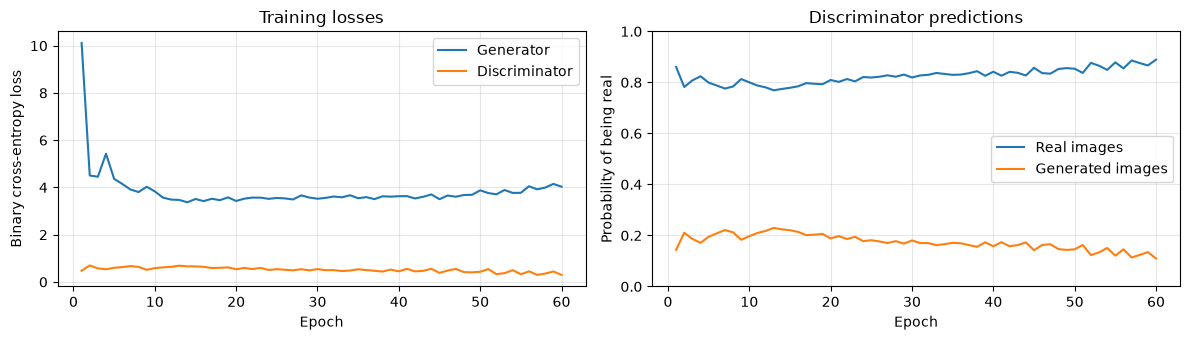

In [10]:
epochs = range(1, len(loss_history.g_losses) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(epochs, loss_history.g_losses, label="Generator")
axes[0].plot(epochs, loss_history.d_losses, label="Discriminator")
axes[0].set_ylabel("Binary cross-entropy loss")
axes[1].plot(epochs, loss_history.d_real, label="Real images")
axes[1].plot(epochs, loss_history.d_fake, label="Generated images")
axes[1].set_ylabel("Probability of being real")
axes[0].set_title("Training losses")
axes[1].set_title("Discriminator predictions")
axes[1].set_ylim(0, 1)
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.3)
    ax.legend()
fig.tight_layout()
fig.savefig(run_dir / "training_losses.png", dpi=300)
plt.show()

In [11]:
# checkpoint = torch.load(
#     run_dir / "checkpoint.pt", map_location="cpu", weights_only=True
# )
# G.load_state_dict(checkpoint["G"])
# D.load_state_dict(checkpoint["D"])
# g_optimizer.load_state_dict(checkpoint["g_optimizer"])
# d_optimizer.load_state_dict(checkpoint["d_optimizer"])
# loss_history = LossHistory()
# loss_history.g_losses = checkpoint["history"]["g_losses"]
# loss_history.d_losses = checkpoint["history"]["d_losses"]
# loss_history.d_real = checkpoint["history"]["d_real"]
# loss_history.d_fake = checkpoint["history"]["d_fake"]
# loss_history.epoch_seconds = checkpoint["history"]["epoch_seconds"]
# fixed_noise = checkpoint["fixed_noise"].to(device)
# torch.set_rng_state(checkpoint["torch_rng"])
# torch.mps.set_rng_state(checkpoint["mps_rng"])
# loader_rng.set_state(checkpoint["loader_rng"])

## Eval

In [12]:
eval_batch_size = 16
eval_seed = 66

G.eval()
model_device = next(G.parameters()).device

eval_loader = DataLoader(
    eval_dataset, batch_size=eval_batch_size, shuffle=False, drop_last=False
)

In [13]:
metric_rng = torch.Generator(device="cpu").manual_seed(eval_seed)
fid_metric = FID(device="cpu")
is_metric = InceptionScore(device="cpu")
fid_metric.reset()
is_metric.reset()
G.eval()

with torch.inference_mode():
    for real_images, _ in eval_loader:
        noise = torch.randn(real_images.size(0), z_dim, 1, 1, generator=metric_rng).to(
            model_device
        )
        fake_images = G(noise)
        metric_batches = []
        for images in (fake_images, real_images):
            images = ((images.detach().cpu() + 1) / 2).clamp(0, 1)
            resized = []
            for image in images:
                pil_image = transforms.functional.to_pil_image(image)
                pil_image = pil_image.resize((299, 299), Image.Resampling.BILINEAR)
                resized.append(transforms.functional.to_tensor(pil_image))
            metric_batches.append(torch.stack(resized))
        fake, real = metric_batches
        fid_metric.update((fake, real))
        is_metric.update(fake)

results = {
    "fid": float(fid_metric.compute()),
    "inception_score": float(is_metric.compute()),
    "epoch": len(loss_history.g_losses),
}
with (run_dir / "metrics.json").open("w") as f:
    json.dump(results, f, indent=2)
print(json.dumps(results, indent=2))

{
  "fid": 0.039146648428484504,
  "inception_score": 2.9070471334332497,
  "epoch": 60
}


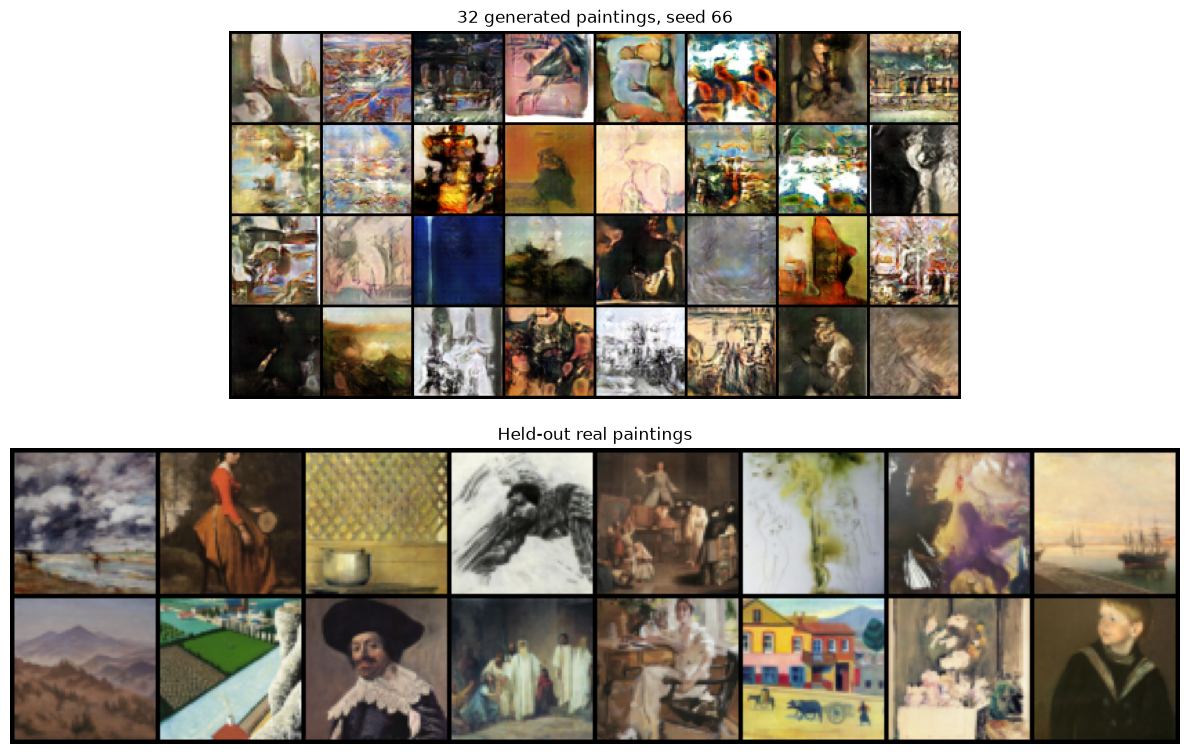

In [14]:
figure_rng = torch.Generator(device="cpu").manual_seed(eval_seed)
G.eval()
with torch.inference_mode():
    noise = torch.randn(32, z_dim, 1, 1, generator=figure_rng).to(model_device)
    samples = ((G(noise).cpu() + 1) / 2).clamp(0, 1)
real_examples = ((next(iter(eval_loader))[0] + 1) / 2).clamp(0, 1)
sample_grid = make_grid(samples, nrow=8, padding=2)
real_grid = make_grid(real_examples, nrow=8, padding=2)
save_image(sample_grid, run_dir / "generated_samples.png")
save_image(real_grid, run_dir / "real_examples.png")
fig, axes = plt.subplots(2, 1, figsize=(12, 8))
axes[0].imshow(sample_grid.permute(1, 2, 0).numpy())
axes[0].set_title("32 generated paintings, seed 66")
axes[1].imshow(real_grid.permute(1, 2, 0).numpy())
axes[1].set_title("Held-out real paintings")
for ax in axes:
    ax.axis("off")
fig.tight_layout()
fig.savefig(run_dir / "report_samples.png", dpi=300)
plt.show()

## latent interpolation

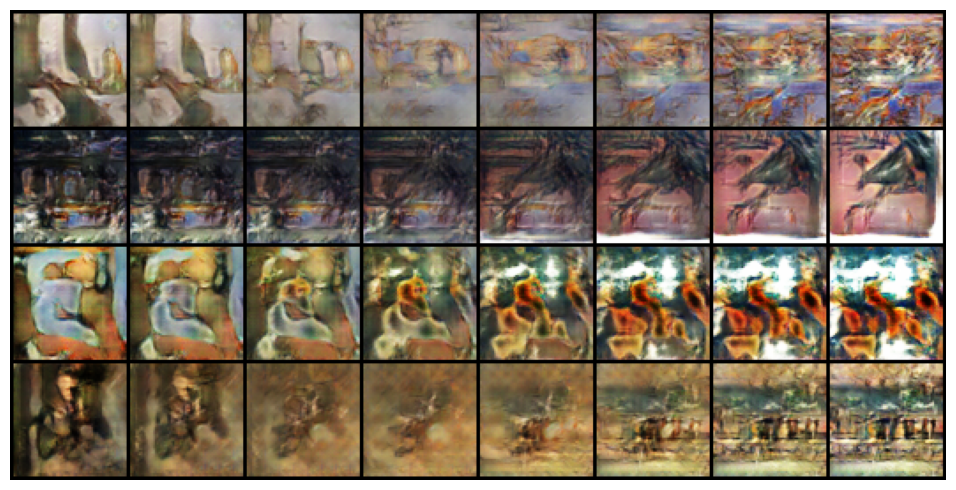

In [15]:
interpolation_rng = torch.Generator(device="cpu").manual_seed(seed)
endpoints = torch.randn(4, 2, z_dim, 1, 1, generator=interpolation_rng)
alpha = torch.linspace(0, 1, 8).view(1, 8, 1, 1, 1)
noise = ((1 - alpha) * endpoints[:, :1] + alpha * endpoints[:, 1:]).reshape(
    -1, z_dim, 1, 1
)
with torch.inference_mode():
    interpolated = ((G(noise.to(model_device)).cpu() + 1) / 2).clamp(0, 1)
interpolation_grid = make_grid(interpolated, nrow=8)
save_image(interpolation_grid, run_dir / "latent_interpolation.png")
plt.figure(figsize=(10, 5))
plt.imshow(interpolation_grid.permute(1, 2, 0).numpy())
plt.axis("off")
plt.tight_layout()
plt.show()